# Security Uncertainty (SU) Index for Nigeria (newspaper-based)

This notebook follows the same approach as the `epu_wp_scraper.py` EPU pipeline: Baker, Bloom & Davis (2016) style. Here it measures **security uncertainty** instead of economic policy uncertainty.

**What counts as an SU article:** an article that contains **at least one uncertainty term** *and* **at least one security term**. Terms match whole words, so "bandit" does not match "abandon".

**Index construction** (same method as the EPU code):
1. For each newspaper *j* and month *t*: $S_{jt} = \dfrac{\text{SU articles}_{jt}}{\text{all articles}_{jt}}$
2. Standardise each paper by its own standard deviation over the period: $N_{jt} = S_{jt} / \sigma_j$
3. Average across papers: $M_t = \text{mean}_j(N_{jt})$
4. Rescale so the period mean is 100: $SU_t = 100 \cdot M_t / \overline{M}$



In [1]:
# @title 1) Settings: choose period, newspapers and mode { display-mode: "form" }
START_DATE = "2025-01-01"  # @param {type:"date"}
END_DATE   = "2026-09-30"  # @param {type:"date"}

# FAST = server-side search prefilter (recommended, minutes).
# FULL = download every article (like the old EPU script; much slower, use only for validation).
MODE = "FAST"  # @param ["FAST", "FULL"]

# --- Newspapers (most circulated / most read in Nigeria). Tick to include. ---
USE_PUNCH          = True   # @param {type:"boolean"}
USE_VANGUARD       = True   # @param {type:"boolean"}
USE_GUARDIAN       = True   # @param {type:"boolean"}
USE_THISDAY        = True   # @param {type:"boolean"}
USE_DAILY_TRUST    = True   # @param {type:"boolean"}
USE_PREMIUM_TIMES  = True   # @param {type:"boolean"}
# optional extras
USE_THE_NATION     = False  # @param {type:"boolean"}
USE_TRIBUNE        = False  # @param {type:"boolean"}
USE_THE_SUN        = False  # @param {type:"boolean"}
USE_LEADERSHIP     = False  # @param {type:"boolean"}

# Use the extended uncertainty list (adds fear/panic/tension wording common in security reporting)
EXTENDED_UNCERTAINTY = False  # @param {type:"boolean"}

# Save cache + outputs to Google Drive (survives runtime resets; makes monthly updates very fast)
USE_GOOGLE_DRIVE = False  # @param {type:"boolean"}
DRIVE_FOLDER = "SU_Index_Nigeria"  # @param {type:"string"}

# Speed controls
PER_SITE_CONCURRENCY = 4   # @param {type:"slider", min:1, max:8, step:1}
TOTAL_WORKERS        = 32  # @param {type:"slider", min:4, max:64, step:4}
REQUEST_TIMEOUT      = 40  # @param {type:"integer"}

ALL_SITES = [
    # (name, base_url, enabled)
    ("Punch",         "https://punchng.com",              USE_PUNCH),
    ("Vanguard",      "https://www.vanguardngr.com",      USE_VANGUARD),
    ("The Guardian",  "https://guardian.ng",              USE_GUARDIAN),
    ("ThisDay",       "https://www.thisdaylive.com",      USE_THISDAY),
    ("Daily Trust",   "https://dailytrust.com",           USE_DAILY_TRUST),
    ("Premium Times", "https://www.premiumtimesng.com",   USE_PREMIUM_TIMES),
    ("The Nation",    "https://thenationonlineng.net",    USE_THE_NATION),
    ("Tribune",       "https://tribuneonlineng.com",      USE_TRIBUNE),
    ("The Sun",       "https://sunnewsonline.com",        USE_THE_SUN),
    ("Leadership",    "https://leadership.ng",            USE_LEADERSHIP),
]
SITES = [(n, u.rstrip("/")) for n, u, on in ALL_SITES if on]
print(f"Period: {START_DATE} → {END_DATE} | Mode: {MODE} | Papers: {[n for n,_ in SITES]}")

Period: 2025-01-01 → 2026-09-30 | Mode: FAST | Papers: ['Punch', 'Vanguard', 'The Guardian', 'ThisDay', 'Daily Trust', 'Premium Times']


In [2]:
# @title 2) Imports and output folder { display-mode: "form" }
import re, json, math, time, html, hashlib, threading, datetime as dt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from collections import defaultdict

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if USE_GOOGLE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    BASE_DIR = Path("/content/su_output") if IN_COLAB else Path("su_output")
CACHE_DIR = BASE_DIR / "cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

SD = dt.date.fromisoformat(START_DATE)
ED = dt.date.fromisoformat(END_DATE)
assert ED >= SD, "END_DATE must not be before START_DATE"
print("Outputs folder:", BASE_DIR.resolve())

Outputs folder: C:\Users\pingc\OneDrive\Documents\Security-Index\su_output


C:\Users\pingc\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Term dictionaries
Edit these lists freely. The cache key includes the dictionaries, so changing a term automatically triggers a re-scrape.

* `SEARCH_WORDS` are the **whole words** sent to the WordPress search in FAST mode. Every word that `UNCERTAINTY_PATTERNS` can match must appear here.
* Generic words like *security*, *attack* or *crisis* are deliberately left out of the security list. They also appear in *food security*, *cyber-attack* and sports reports. Specific phrases such as *security forces* are used instead.

In [3]:
# @title 3) Security & uncertainty dictionaries { display-mode: "form" }
# --- Uncertainty (BBD core, same as the EPU script + 'instability'/'unpredictability') ---
UNCERTAINTY_CORE = {
    # regex pattern            : words to send to WP search (FAST mode)
    r"uncertain(?:ty|ties)?"   : ["uncertain", "uncertainty", "uncertainties"],
    r"unpredictab(?:le|ility)" : ["unpredictable", "unpredictability"],
    r"unclear"                 : ["unclear"],
    r"unstable"                : ["unstable"],
    r"instability"             : ["instability"],
}
UNCERTAINTY_EXTENDED = {
    r"fears?"                  : ["fear", "fears"],
    r"panic"                   : ["panic"],
    r"apprehension"            : ["apprehension"],
    r"tension"                 : ["tension"],
    r"volatile|volatility"     : ["volatile", "volatility"],
}
UNC_MAP = dict(UNCERTAINTY_CORE, **(UNCERTAINTY_EXTENDED if EXTENDED_UNCERTAINTY else {}))
UNCERTAINTY_PATTERNS = list(UNC_MAP.keys())
SEARCH_WORDS = sorted({w for ws in UNC_MAP.values() for w in ws})

# --- Security (Nigeria-specific threats, actors and responses) ---
SECURITY_PATTERNS = [
    r"insecurity", r"insurgen(?:cy|ts?)", r"terror(?:ism|ists?|ist attacks?)",
    r"boko haram", r"iswap", r"ansaru", r"lakurawa", r"jihadis(?:ts?|m)",
    r"bandit(?:s|ry)?", r"kidnap(?:s|ped|ping|pers?)?", r"abduct(?:s|ed|ion|ions|ors?)?",
    r"ransom", r"gunmen", r"unknown gunmen", r"armed (?:men|robbery|robbers|herders)",
    r"herdsmen", r"farmers?[- ]herders?", r"militan(?:ts?|cy)", r"cult(?:ists?|ism|-related)",
    r"ipob", r"eastern security network", r"secessionists?", r"sit-at-home",
    r"killings?", r"massacre", r"bomb(?:s|ing|ings|ed)?", r"explosions?", r"ied",
    r"suicide bombers?", r"vandal(?:s|ism|ised|ized)", r"pipeline vandal\w*", r"oil theft",
    r"communal (?:clash(?:es)?|crisis|violence)", r"ethnic (?:clash(?:es)?|violence)",
    r"security (?:forces|agencies|operatives|personnel|situation|challenges?|threats?|breach(?:es)?|architecture)",
    r"military (?:operations?|offensive|airstrikes?)", r"air ?strikes?", r"troops",
    r"state of emergency", r"curfew", r"coup(?: plot| attempt)?",
]

def _compile(patterns):
    return re.compile(r"\b(?:" + "|".join(patterns) + r")\b", re.IGNORECASE)

UNC_RE = _compile(UNCERTAINTY_PATTERNS)
SEC_RE = _compile(SECURITY_PATTERNS)

# cache key changes whenever dictionaries / mode change
DICT_HASH = hashlib.md5(json.dumps([MODE, UNCERTAINTY_PATTERNS, SEARCH_WORDS, SECURITY_PATTERNS]).encode()).hexdigest()[:10]
print(f"{len(UNCERTAINTY_PATTERNS)} uncertainty patterns | {len(SEARCH_WORDS)} search words | {len(SECURITY_PATTERNS)} security patterns | key={DICT_HASH}")

5 uncertainty patterns | 8 search words | 41 security patterns | key=56e8e5e159


In [4]:
# @title 4) Fast HTTP layer + WordPress fetchers { display-mode: "form" }
_tls = threading.local()
SITE_SEM = defaultdict(lambda: threading.BoundedSemaphore(PER_SITE_CONCURRENCY))
BLOCKED = {}          # site -> reason
UA = ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
      "(KHTML, like Gecko) Chrome/124.0 Safari/537.36")

def _session():
    s = getattr(_tls, "s", None)
    if s is None:
        s = requests.Session()
        retry = Retry(total=4, backoff_factor=0.8, status_forcelist=[429, 500, 502, 503, 504],
                      allowed_methods=["GET"], raise_on_status=False, respect_retry_after_header=True)
        ad = HTTPAdapter(max_retries=retry, pool_connections=16, pool_maxsize=16)
        s.mount("https://", ad); s.mount("http://", ad)
        s.headers.update({"User-Agent": UA, "Accept": "application/json", "Accept-Language": "en-GB,en;q=0.9"})
        _tls.s = s
    return s

class SiteBlocked(Exception):
    pass

def wp_get(site, base, params):
    """One GET to /wp-json/wp/v2/posts. Returns (json_list, headers)."""
    if site in BLOCKED:
        raise SiteBlocked(BLOCKED[site])
    with SITE_SEM[site]:
        r = _session().get(f"{base}/wp-json/wp/v2/posts", params=params, timeout=REQUEST_TIMEOUT)
    if r.status_code == 400 and "rest_post_invalid_page_number" in r.text:
        return [], r.headers
    if r.status_code in (401, 403, 406, 451):
        BLOCKED[site] = f"HTTP {r.status_code}"
        raise SiteBlocked(BLOCKED[site])
    r.raise_for_status()
    if "json" not in r.headers.get("Content-Type", ""):
        BLOCKED[site] = "non-JSON reply (bot protection page)"
        raise SiteBlocked(BLOCKED[site])
    return r.json(), r.headers

FIELDS = "id,date,link,title,excerpt,content"
PER_PAGE = 100   # WordPress maximum

def month_windows(sd, ed):
    """Split [sd, ed] into calendar-month windows (partial at the edges)."""
    out, cur = [], dt.date(sd.year, sd.month, 1)
    while cur <= ed:
        nxt = dt.date(cur.year + (cur.month == 12), cur.month % 12 + 1, 1)
        out.append((cur, max(sd, cur), min(ed, nxt - dt.timedelta(days=1))))
        cur = nxt
    return out

def base_params(w0, w1):
    # 'after' and 'before' are exclusive in WP; widen by one second / one day
    return {"after": f"{(w0 - dt.timedelta(days=1)).isoformat()}T23:59:59",
            "before": f"{(w1 + dt.timedelta(days=1)).isoformat()}T00:00:00",
            "orderby": "date", "order": "asc"}

def tag_post(p):
    title = html.unescape(re.sub(r"<[^>]+>", " ", (p.get("title") or {}).get("rendered") or ""))
    body = " ".join([(p.get("excerpt") or {}).get("rendered") or "", (p.get("content") or {}).get("rendered") or ""])
    text = html.unescape(re.sub(r"<[^>]+>", " ", title + " " + body))
    u = UNC_RE.findall(text)
    s = SEC_RE.findall(text) if u or MODE == "FULL" else []
    return {"id": p.get("id"), "date": (p.get("date") or "")[:10], "title": title.strip(),
            "url": p.get("link", ""), "has_unc": bool(u), "has_sec": bool(s),
            "unc_terms": "; ".join(sorted({x.lower() for x in u})),
            "sec_terms": "; ".join(sorted({x.lower() for x in s}))}

def site_check(name, base):
    try:
        data, h = wp_get(name, base, {"per_page": 1, "_fields": "id"})
        return name, "OK", int(h.get("X-WP-Total", 0))
    except Exception as e:
        return name, f"BLOCKED/ERROR: {str(e)[:80]}", 0

In [5]:
# @title 5) Check which newspapers are reachable from this runtime { display-mode: "form" }
with ThreadPoolExecutor(len(SITES) or 1) as ex:
    checks = list(ex.map(lambda s: site_check(*s), SITES))
for n, st, tot in checks:
    print(f"  {n:<15} {st:<45} {'(archive: %s posts)' % f'{tot:,}' if tot else ''}")
ACTIVE = [(n, u) for (n, u), (_, st, _) in zip(SITES, checks) if st == "OK"]
if len(ACTIVE) < len(SITES):
    print("\n⚠️  Unreachable papers are skipped. Tip: Runtime → Disconnect and delete runtime, then rerun "
          "(you get a new IP address), or run this notebook locally in Jupyter.")
for n, _ in SITES:
    BLOCKED.pop(n, None)   # give blocked ones a fresh chance during the main run
print(f"\nScraping {len(ACTIVE)} paper(s): {[n for n,_ in ACTIVE]}")

  Punch           BLOCKED/ERROR: HTTP 403                       
  Vanguard        BLOCKED/ERROR: HTTP 403                       
  The Guardian    OK                                            (archive: 632,649 posts)
  ThisDay         OK                                            (archive: 1 posts)
  Daily Trust     OK                                            (archive: 562,348 posts)
  Premium Times   OK                                            (archive: 220,429 posts)

⚠️  Unreachable papers are skipped. Tip: Runtime → Disconnect and delete runtime, then rerun (you get a new IP address), or run this notebook locally in Jupyter.

Scraping 4 paper(s): ['The Guardian', 'ThisDay', 'Daily Trust', 'Premium Times']


In [6]:
# @title 6) Scrape (parallel, cached). FAST mode usually takes a few minutes { display-mode: "form" }
TODAY = dt.date.today()

def cache_path(site, mkey):
    return CACHE_DIR / f"{re.sub(r'[^A-Za-z0-9]+','_',site)}_{mkey}_{DICT_HASH}.json"

def run_parallel(tasks, fn, desc):
    """tasks: list of args tuples. Returns list of (args, result_or_exception)."""
    out = []
    if not tasks:
        return out
    with ThreadPoolExecutor(min(TOTAL_WORKERS, len(tasks))) as ex:
        futs = {ex.submit(fn, *t): t for t in tasks}
        for f in tqdm(as_completed(futs), total=len(futs), desc=desc):
            try:
                out.append((futs[f], f.result()))
            except Exception as e:
                out.append((futs[f], e))
    return out

t0 = time.time()
windows = month_windows(SD, ED)

# --- 0. load cache for completed full months ---
results = {}   # (site, mkey) -> dict(total, unc, su, articles)
todo = []
for name, base in ACTIVE:
    for m0, w0, w1 in windows:
        mkey = m0.strftime("%Y-%m")
        full_month = (w0 == m0) and (w1.month != (w1 + dt.timedelta(days=1)).month)
        cp = cache_path(name, mkey)
        if full_month and cp.exists():
            results[(name, mkey)] = json.loads(cp.read_text())
        else:
            todo.append((name, base, mkey, w0, w1, full_month))
print(f"{len(results)} site-months loaded from cache, {len(todo)} to scrape.")

# --- 1. first-page requests: totals + page 1 of every query ---
def first_page(name, base, mkey, w0, w1, query):
    p = dict(base_params(w0, w1))
    if query == "__TOTAL__":
        p.update(per_page=1, _fields="id")
        _, h = wp_get(name, base, p)
        return {"total": int(h.get("X-WP-Total", 0)), "pages": 0, "posts": []}
    if query is not None:
        p["search"] = query
    p.update(per_page=PER_PAGE, _fields=FIELDS, page=1)
    data, h = wp_get(name, base, p)
    return {"total": int(h.get("X-WP-Total", len(data))), "pages": int(h.get("X-WP-TotalPages", 1)),
            "posts": [tag_post(x) for x in data]}

def page_n(name, base, mkey, w0, w1, query, page):
    p = dict(base_params(w0, w1))
    if query is not None:
        p["search"] = query
    p.update(per_page=PER_PAGE, _fields=FIELDS, page=page)
    data, _ = wp_get(name, base, p)
    return [tag_post(x) for x in data]

queries = (["__TOTAL__"] + SEARCH_WORDS) if MODE == "FAST" else [None]
tasks1 = [(n, b, mk, w0, w1, q) for (n, b, mk, w0, w1, _) in todo for q in queries]
res1 = run_parallel(tasks1, first_page, "Step 1/2 first pages")

acc = defaultdict(lambda: {"total": 0, "posts": {}, "errors": 0})
tasks2 = []
for (n, b, mk, w0, w1, q), r in res1:
    a = acc[(n, mk)]
    if isinstance(r, Exception):
        a["errors"] += 1; continue
    if q == "__TOTAL__" or q is None:
        a["total"] = r["total"]
    for post in r["posts"]:
        a["posts"][post["id"]] = post
    tasks2 += [(n, b, mk, w0, w1, q, pg) for pg in range(2, r["pages"] + 1)]

# --- 2. remaining pages, all in parallel ---
res2 = run_parallel(tasks2, page_n, "Step 2/2 remaining pages")
for (n, b, mk, w0, w1, q, pg), r in res2:
    a = acc[(n, mk)]
    if isinstance(r, Exception):
        a["errors"] += 1; continue
    for post in r:
        a["posts"][post["id"]] = post

# --- 3. summarise each site-month, cache completed months ---
failed = []
for (n, b, mk, w0, w1, full_month) in todo:
    a = acc[(n, mk)]
    posts = a["posts"].values()
    su_posts = [p for p in posts if p["has_unc"] and p["has_sec"]]
    rec = {"site": n, "month": mk, "total": a["total"],
           "unc": sum(p["has_unc"] for p in posts), "su": len(su_posts),
           "articles": sorted(su_posts, key=lambda p: p["date"])}
    if a["errors"]:
        failed.append((n, mk, a["errors"]))
        continue          # don't use or cache incomplete months
    results[(n, mk)] = rec
    if full_month and w1 < TODAY and a["total"] > 0:
        cache_path(n, mk).write_text(json.dumps(rec))

print(f"\n✅ Done in {time.time()-t0:,.1f}s | requests: {len(tasks1)+len(tasks2):,}")
if BLOCKED:
    print("⚠️  Blocked during run:", BLOCKED)
if failed:
    print(f"⚠️  {len(failed)} site-month(s) had request errors and were EXCLUDED (rerun this cell to retry; "
          "completed months are cached):", failed[:10], "..." if len(failed) > 10 else "")

0 site-months loaded from cache, 84 to scrape.


Step 1/2 first pages:   0%|          | 0/756 [00:00<?, ?it/s]

Step 1/2 first pages:   0%|          | 1/756 [00:00<04:44,  2.65it/s]

Step 1/2 first pages:  21%|██▏       | 161/756 [00:00<00:01, 328.01it/s]

Step 1/2 first pages:  27%|██▋       | 203/756 [00:02<00:08, 66.89it/s] 

...

Step 2/2 remaining pages:  94%|█████████▍| 32/34 [00:09<00:00,  3.02it/s]

Step 2/2 remaining pages:  97%|█████████▋| 33/34 [00:09<00:00,  3.02it/s]

Step 2/2 remaining pages: 100%|██████████| 34/34 [00:09<00:00,  3.65it/s]

Step 2/2 remaining pages: 100%|██████████| 34/34 [00:09<00:00,  3.46it/s]


✅ Done in 34.8s | requests: 790
⚠️  Blocked during run: {'The Guardian': 'HTTP 403', 'Premium Times': 'non-JSON reply (bot protection page)'}
⚠️  42 site-month(s) had request errors and were EXCLUDED (rerun this cell to retry; completed months are cached): [('The Guardian', '2025-01', 8), ('The Guardian', '2025-02', 8), ('The Guardian', '2025-03', 8), ('The Guardian', '2025-04', 8), ('The Guardian', '2025-05', 9), ('The Guardian', '2025-06', 9), ('The Guardian', '2025-07', 9), ('The Guardian', '2025-08', 9), ('The Guardian', '2025-09', 9), ('The Guardian', '2025-10', 9)] ...


In [7]:
# @title 7) Compute the SU index (same standardisation as the EPU code) { display-mode: "form" }
panel = pd.DataFrame([{k: v for k, v in r.items() if k != "articles"} for r in results.values()])
if panel.empty:
    raise SystemExit("No data scraped. Check the site check in Cell 5.")
panel["month"] = pd.to_datetime(panel["month"])
panel = panel.sort_values(["site", "month"]).reset_index(drop=True)

def compute_su_index(panel):
    d = panel[panel["total"] > 0].copy()
    d["S"] = d["su"] / d["total"]                                   # share
    d["sigma"] = d.groupby("site")["S"].transform("std")            # per-paper dispersion
    d["N"] = d["S"] / d["sigma"].replace(0, np.nan)                 # standardised
    M = d.groupby("month")["N"].mean()                              # average across papers
    idx = pd.DataFrame({"M": M, "SU_index": 100 * M / M.mean(),
                        "papers": d.groupby("month")["site"].nunique(),
                        "total_articles": d.groupby("month")["total"].sum(),
                        "su_articles": d.groupby("month")["su"].sum()})
    idx["su_share_%"] = 100 * idx["su_articles"] / idx["total_articles"]
    return idx, d

su_index, panel_std = compute_su_index(panel)
if panel_std.groupby("site")["month"].nunique().min() < 2:
    print("⚠️  Fewer than 2 months for some paper. σ is undefined there; choose a longer period.")

articles = pd.DataFrame([a | {"site": r["site"]} for r in results.values() for a in r["articles"]])

# Save
tag = f"{SD}_{ED}"
su_index.to_csv(BASE_DIR / f"SU_index_{tag}.csv", date_format="%Y-%m-%d")
panel_std.to_csv(BASE_DIR / f"SU_panel_by_paper_{tag}.csv", index=False, date_format="%Y-%m-%d")
if not articles.empty:
    articles[["site","date","title","url","unc_terms","sec_terms"]].to_csv(BASE_DIR / f"SU_articles_{tag}.csv", index=False)

print("Articles per paper (whole period):")
print(panel.groupby("site")[["total","unc","su"]].sum().rename(columns={"unc":"uncertainty","su":"SU"}).to_string())
print()
display(su_index.round(2)) if IN_COLAB else print(su_index.round(2))

Articles per paper (whole period):
             total  uncertainty    SU
site                                 
Daily Trust  57150         3184  1320
ThisDay         21          238    56

               M  SU_index  papers  total_articles  su_articles  su_share_%
month                                                                      
2025-01-01  1.38     68.17       2            2872           48        1.67
2025-02-01  1.15     56.80       2            2657           37        1.39
2025-03-01  1.93     95.30       2            2996           70        2.34
2025-04-01  1.74     85.99       2            2609           55        2.11
2025-05-01  1.52     75.20       2            2712           50        1.84
2025-06-01  2.29    113.17       2            2379           66        2.77
2025-07-01  1.55     76.40       2            2723           51        1.87
2025-08-01  1.57     77.72       2            2467           47        1.91
2025-09-01  1.45     71.41       2            2742  

## Plots
Optionally fill in `ANNOTATIONS` with event labels, as in `epu_trend_JantoOct.py`. Cell 9 lists each month's top SU headlines to help you pick the labels.

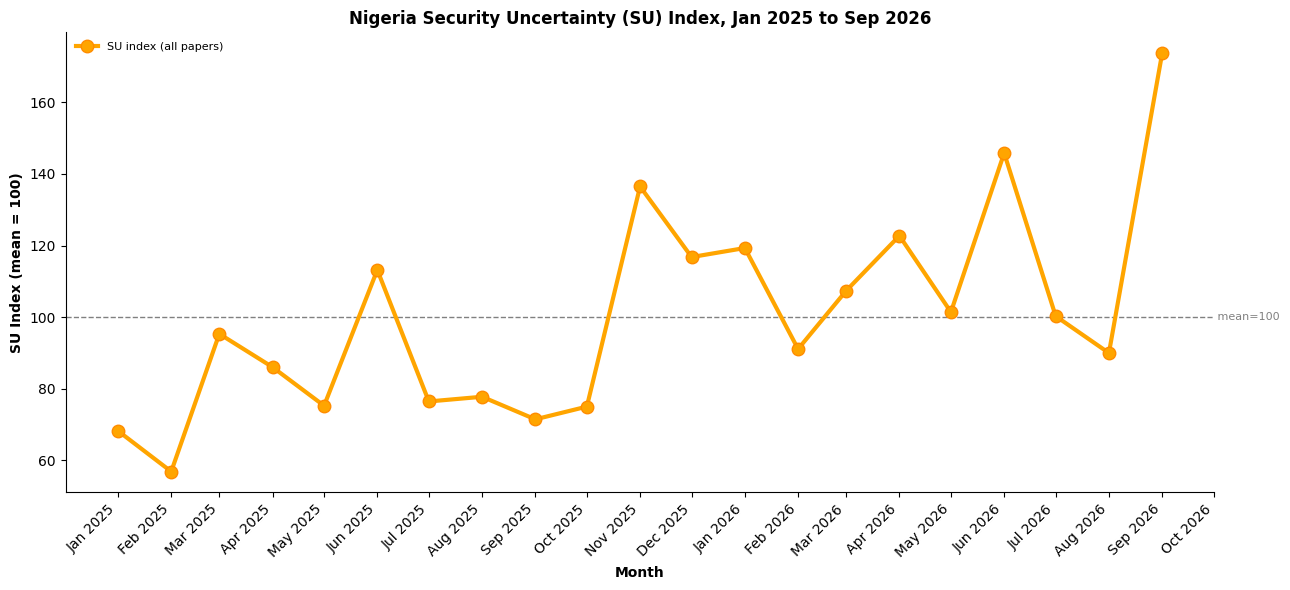

Saved: su_output\SU_index_chart_2025-01-01_2026-09-30.png


In [8]:
# @title 8) Plot the SU index for the selected period { display-mode: "form" }
ANNOTATIONS = {
    # "2025-03": "State of emergency (Rivers)",
    # "2025-11": "Kebbi schoolgirls abduction",
}
SHOW_PAPER_LINES = False  # @param {type:"boolean"}

s = su_index["SU_index"]
fig, ax = plt.subplots(figsize=(13, 6))
if SHOW_PAPER_LINES and panel_std["site"].nunique() > 1:
    pal = [c for i, c in enumerate(plt.get_cmap("tab10").colors) if i != 1]  # skip orange
    scale = panel_std.groupby("month")["N"].mean().mean()
    for i, (site, g) in enumerate(panel_std.groupby("site")):
        g = g.set_index("month")["N"]
        ax.plot(g.index, 100 * g / scale, lw=1.2, alpha=0.45, color=pal[i % len(pal)], label=site)
ax.plot(s.index, s.values, marker="o", color="orange", lw=3, ms=9,
        markeredgecolor="darkorange", label="SU index (all papers)", zorder=5)
ax.axhline(100, ls="--", lw=1, color="grey")
ax.text(1.0, 100, " mean=100", transform=ax.get_yaxis_transform(), color="grey", fontsize=8, va="center")

for k, label in ANNOTATIONS.items():
    t = pd.Timestamp(k + "-01")
    if t in s.index:
        ax.annotate(label, xy=(t, s[t]), xytext=(0, 14), textcoords="offset points", ha="center",
                    fontsize=8, fontweight="bold", color="blue",
                    arrowprops=dict(arrowstyle="->", lw=0.8, color="blue"))

for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=max(1, len(s)//18)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_title(f"Nigeria Security Uncertainty (SU) Index, {SD:%b %Y} to {ED:%b %Y}", fontweight="bold")
ax.set_xlabel("Month", fontweight="bold"); ax.set_ylabel("SU Index (mean = 100)", fontweight="bold")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
png = BASE_DIR / f"SU_index_chart_{SD}_{ED}.png"
plt.savefig(png, dpi=300, bbox_inches="tight")
plt.show()
print("Saved:", png)

In [9]:
# @title 9) Top SU headlines per month (helps with annotations) { display-mode: "form" }
TOP_N = 3  # @param {type:"integer"}
if not articles.empty:
    a = articles.copy()
    a["month"] = pd.to_datetime(a["date"]).dt.to_period("M")
    a["n_sec"] = a["sec_terms"].str.count(";") + 1
    a["rank"] = a.sort_values("n_sec", ascending=False).groupby(["month", "site"]).cumcount()
    for m, g in a.sort_values(["rank", "n_sec"], ascending=[True, False]).groupby("month"):  # spread across papers
        print(f"\n{m.strftime('%b %Y')}  (SU index {su_index['SU_index'].get(m.to_timestamp(), float('nan')):.1f})")
        for _, r in g.head(TOP_N).iterrows():
            print(f"   [{r['site']}] {r['title'][:110]}  →  {r['sec_terms']}")


Jan 2025  (SU index 68.2)
   [Daily Trust] Inside bandits’ hideouts: A journalist’s expedition through notorious camps  →  abducted; abduction; abductions; bandit; banditry; bandits; insecurity; kidnap; kidnapped; kidnapping; killing; killings; ransom; security agencies; security forces
   [Daily Trust] Bandits abduct many passengers, burn vehicle in Zamfara  →  abduct; abducted; airstrikes; bandit; bandits; kidnap; killing; security operatives; terrorist; terrorists; troops
   [Daily Trust] From rails to rifts: Nigeriens, Tinubu’s diplomacy, and the New Year Shege  →  boko haram; coup; insecurity; iswap; lakurawa; security challenges; security forces; terrorism; terrorist; terrorists

Feb 2025  (SU index 56.8)
   [Daily Trust] Abductors of APC nat’l director demand N350m ransom  →  abduct; abducted; abduction; abductions; abductors; bandits; gunmen; kidnapped; kidnappers; ransom; security agencies; security personnel
   [Daily Trust] PAKISTAN: Child safety measures under scrutiny ami

In [10]:
# @title 10) Download all outputs as a zip { display-mode: "form" }
import shutil
zip_path = shutil.make_archive(str(BASE_DIR.parent / f"SU_outputs_{SD}_{ED}"), "zip", BASE_DIR, ".")
print("Zipped:", zip_path)
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

Zipped: C:\Users\pingc\OneDrive\Documents\Security-Index\SU_outputs_2025-01-01_2026-09-30.zip


## Optional: validate FAST against FULL for one paper-month
FAST mode should give exactly the same SU count as downloading everything, because it only skips articles with no uncertainty word. The next cell checks this for one paper and month by downloading every article for that month. This takes about a minute.

In [11]:
# @title 11) (Optional) FAST vs FULL check for one paper-month { display-mode: "form" }
RUN_CHECK = False  # @param {type:"boolean"}
CHECK_PAPER = "Premium Times"  # @param {type:"string"}
CHECK_MONTH = "2025-06"  # @param {type:"string"}
if RUN_CHECK:
    base = dict(SITES)[CHECK_PAPER]
    m0 = dt.date.fromisoformat(CHECK_MONTH + "-01")
    m1 = dt.date(m0.year + (m0.month == 12), m0.month % 12 + 1, 1) - dt.timedelta(days=1)
    _MODE = MODE; MODE = "FULL"
    first = first_page(CHECK_PAPER, base, CHECK_MONTH, m0, m1, None)
    rest = run_parallel([(CHECK_PAPER, base, CHECK_MONTH, m0, m1, None, p) for p in range(2, first["pages"] + 1)],
                        page_n, "full download")
    MODE = _MODE
    allp = {p["id"]: p for p in first["posts"]}
    for _, r in rest:
        if not isinstance(r, Exception):
            allp.update({p["id"]: p for p in r})
    full_su = sum(p["has_unc"] and p["has_sec"] for p in allp.values())
    fast = results.get((CHECK_PAPER, CHECK_MONTH), {})
    print(f"FULL: total={first['total']:,} downloaded={len(allp):,} SU={full_su}")
    print(f"FAST: total={fast.get('total')} SU={fast.get('su')}")